# Qubit Emulation

NicDeclic  
2026-11-06

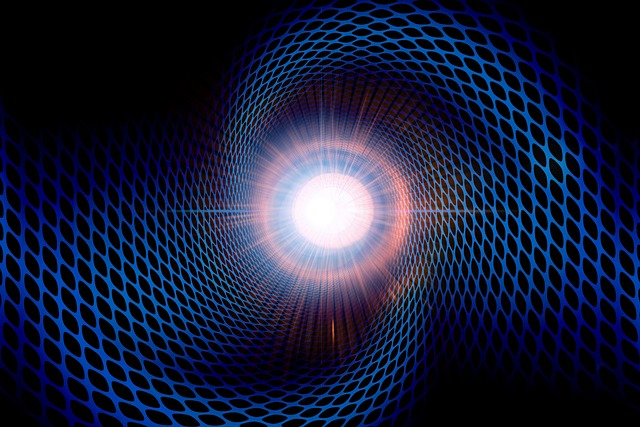

> *“Sometimes, unlearning is the highest form of wisdom.”*  
> — **Professor Alvin**

------------------------------------------------------------------------

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nicdeclic/quantum-molecular-computing/blob/main/posts/quantum-chemistry/index.ipynb)

In [1]:
import sys
if 'google.colab' in sys.modules:
    # 1. Download qmc.py from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/qmc.py
    
    # 2. Download requirements.txt from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/requirements.txt

    # 3. Install dependencies
    !pip install -q -r requirements.txt

sys.path.insert(0, "../../src") # Select root directory
from qmc import * # QMC library

%reload_ext autoreload
%autoreload 2

------------------------------------------------------------------------

> **📝 A Quick Note on Mathematical Notation**
>
> Because this specific post directly investigates the mapping between
> standard quantum computing and the CCC molecular model, you will
> occasionally encounter standard **Dirac bra-ket notation**
> ($|0\rangle, |1\rangle, |\psi\rangle$) alongside complex unitary
> matrices.
>
> This is done to provide a clear, unambiguous bridge for readers
> familiar with conventional quantum mechanics, making the mathematical
> translation into the protobit framework as transparent as possible.

## Representing a Qubit with Protobits

On the surface, qubits and protobits appear fundamentally incompatible:

- **Qubits** are described by state vectors with negative and complex
  probability amplitudes ($\mathbb{C}^2$). This complex phase allows
  wavefunctions to interfere constructively or destructively (adding or
  subtracting amplitudes).  
- **Protobits**, operating within stochastic transition matrices, are
  defined purely over real, non-negative probabilities ($p \in [0, 1]$),
  with no native complex phase.

Yet, we have already proven that the molecular gates achieve universal
computation. Any mathematical operation—including complex arithmetic and
phase rotations—can be synthesized algebraically.

All that is required now is the optimal geometric mapping.

### Deconstructing the Bloch Sphere

Geometrically, a single qubit lives on the continuous surface of a
three-dimensional unit sphere: the **Bloch Sphere**.

To reconstruct the full expressive richness of a spherical state space
using only positive-probability protobits, linear algebra dictates that
we need a minimum of **three independent dimensions**.

To completely define the state of a qubit without invoking imaginary
numbers in the underlying hardware, we decompose the state across
**three distinct functional protobits**:

1.  **The Presence Protobit ($A_2$):**  
    Encodes the vertical projection (along the $Z$-axis), determining
    whether the measurement collapses toward $|0\rangle$ or
    $|1\rangle$.  
2.  **The Imaginary Phase Protobit ($A_1$):**  
    Governs circular phase along the $Y$-axis, encoding the imaginary
    depth of the quantum state ($+1$ or $+i$).  
3.  **The Sign Phase Protobit ($A_0$):**  
    Governs real interference along the $X$-axis, determining whether
    wave amplitudes add constructively ($+1$) or destructively ($-1$).

------------------------------------------------------------------------

### The 8 Extremal Basis States

When these three protobits are combined through the Kronecker product,
they span an 8-dimensional configuration space ($2^3 = 8$).

These 8 discrete basis states map directly to the **8 vertices of a
state cube**, perfectly capturing the cardinal projections along with
their fundamental discrete phase orientations ($\pm 1, \pm i$):

$$\text{``000''} \longrightarrow \begin{bmatrix} 1 \\ 0 \end{bmatrix} \longrightarrow |0\rangle$$

$$\text{``001''} \longrightarrow \begin{bmatrix} -1 \\ 0 \end{bmatrix} \longrightarrow -|0\rangle$$

$$\text{``010''} \longrightarrow \begin{bmatrix} i \\ 0 \end{bmatrix} \longrightarrow i|0\rangle$$

$$\text{``011''} \longrightarrow \begin{bmatrix} -i \\ 0 \end{bmatrix} \longrightarrow -i|0\rangle$$

$$\text{``100''} \longrightarrow \begin{bmatrix} 0 \\ 1 \end{bmatrix} \longrightarrow |1\rangle$$

$$\text{``101''} \longrightarrow \begin{bmatrix} 0 \\ -1 \end{bmatrix} \longrightarrow -|1\rangle$$

$$\text{``110''} \longrightarrow \begin{bmatrix} 0 \\ i \end{bmatrix} \longrightarrow i|1\rangle$$

$$\text{``111''} \longrightarrow \begin{bmatrix} 0 \\ -i \end{bmatrix} \longrightarrow -i|1\rangle$$

By taking convex linear combinations (superpositions) across these 8
positive protobit states, we can reconstruct **any arbitrary point**
$(\theta, \phi)$ on the Bloch sphere.

The mystery of complex quantum phases dissolves into real, positive
geometry. Three simple carbon bonds are all that nature needs to house a
complete quantum qubit.

------------------------------------------------------------------------

## Mapping a Continuous Qubit into a 3-Protobit State Vector

How do we take an arbitrary, continuous quantum qubit state
$|\psi\rangle$ defined over complex numbers and convert it into our
discrete, strictly non-negative $1 \times 8$ protobit transition matrix?

A general qubit state is written in Dirac notation as:

$$|\psi\rangle = c_0 |0\rangle + c_1 |1\rangle = \begin{bmatrix} c_0 \\ c_1 \end{bmatrix}$$

where $c_0, c_1 \in \mathbb{C}$ are complex probability amplitudes.

We can expand each complex coefficient into its real and imaginary
parts:

$$c_0 = \text{Re}(c_0) + i \, \text{Im}(c_0)$$
$$c_1 = \text{Re}(c_1) + i \, \text{Im}(c_1)$$

This gives us **4 real numbers**:
$\text{Re}(c_0), \, \text{Im}(c_0), \, \text{Re}(c_1), \, \text{Im}(c_1)$.

However, these real numbers can be negative, whereas our protobit
transition matrices require strictly **non-negative probabilities**
($p \ge 0$).

To eliminate negative numbers without losing any phase information, we
decompose every real value $x$ into its **positive component** ($x^+$)
and **negative component** ($x^-$):

$$x = x^+ - x^- \quad \text{where} \quad x^+ = \max(x, 0), \quad x^- = \max(-x, 0)$$

Notice that $x^+$ and $x^-$ are **both non-negative ($\ge 0$)**, and at
least one of them is always zero!

Applying this split to our 4 real parameters yields exactly **8
non-negative values** ($p_0$ through $p_7$):

$$p_0 = \max({Re}(c_0), 0)$$ $$p_1 = \max({-Re}(c_0), 0)$$
$$p_2 = \max({Im}(c_0), 0)$$ $$p_3 = \max({-Im}(c_0), 0)$$
$$p_4 = \max({Re}(c_1), 0)$$ $$p_5 = \max({-Re}(c_1), 0)$$
$$p_6 = \max({Im}(c_1), 0)$$ $$p_7 = \max({-Im}(c_1), 0)$$

To satisfy the conservation of probability, where all row elements must
sum to $1.0$, we compute the $L_1$-norm scalar:

$$S = \sum_{k=0}^{7} p_k$$

Finally, we normalize each component:

$$\mathbf{P} = \frac{1}{S} \begin{bmatrix} p_0 & p_1 & p_2 & p_3 & p_4 & p_5 & p_6 & p_7 \end{bmatrix}$$

The resulting $1 \times 8$ row vector $\mathbf{P}$ is a valid,
normalized, non-negative probability distribution over our 3 protobits.

Not a single bit of information, amplitude, or complex phase from the
original qubit is lost. It has simply been unpacked into an 8-channel
stochastic representation!

------------------------------------------------------------------------

## Quantum Logic Gates as Cube Rotations

Implementing the continuous rotation of a quantum logic gate might
appear daunting at first glance. In our discrete framework, however, the
problem simplifies drastically: **all we need to specify is where the 8
vertices of our state cube map to.**

Think of tracking an airplane flying across a pitch-black night sky:

Inside the cockpit, the pilot relies on continuous gyroscopes and
altitude instruments. But an observer standing on the ground below
cannot see the fuselage of the plane at all. All they can see are the
plane’s exterior navigation lights:  
\* A **red light** on the left wingtip,  
\* A **green light** on the right wingtip,  
\* A **white beacon** on the tail / belly.

Even though the observer only tracks three discrete points of light,
they can unambiguously deduce the airplane’s full three-dimensional
spatial orientation.

If the observer initially sees the red light on the left, the green
light on the right, and the white beacon underneath—and a moment later
observes the red light on the right, the green light on the left, and
the white beacon on top—they know with absolute mathematical certainty
that the aircraft has executed a **$180^\circ$ roll**.

We treat quantum logic gates in precisely the same way:

We do not need to model an intractable, continuous spherical rotation
across the entire continuum of the Bloch sphere. We simply track the
permutation of our **8 discrete basis vertices**.

By tracking how these extremal “navigation lights” permute across our
protobit coordinates, the global unitary transformation naturally takes
care of itself.

------------------------------------------------------------------------

## Elementary Single-Qubit Gates

The standard Pauli gates—**$X$, $Y$, and $Z$**, along with the phase
gate **$S$**—are classified as “simple” in our framework for two
structural reasons:  
1. They operate strictly on a **single logical qubit** (one 3-protobit
channel in, one 3-protobit channel out).  
2. Every vertex of our 8-state cube maps cleanly and deterministically
onto **another exact vertex of the cube**. There is no splitting of
amplitudes or fractional dispersion across vertices.

Consequently, in this discrete representation, implementing a quantum
gate reduces fundamentally to implementing a **truth table
permutation**.

**Keep in mind that while these circuits are structurally composed of
boolean logic components, they operate as quantum transition operators
capable of manipulating protobit states.** We established their
mathematical foundation earlier in [“A Refresher on Boolean
Logic”](../../posts/boolean-logic/index.html) and [“Boolean Gates
Extensions”](../../posts/quantum-boolean/index.html) using transition
matrix formalism.

------------------------------------------------------------------------

### The X Gate (Pauli-X / Bit-Flip)

The $X$ operator swaps the basis states
$|0\rangle \leftrightarrow |1\rangle$. It corresponds to a $\pi$
($180^\circ$) rotation around the $X$-axis of the Bloch sphere:

$$X = |1\rangle\langle 0| + |0\rangle\langle 1| = \begin{bmatrix} 0 & 1 \\ 1 & 0 \end{bmatrix}$$

- **Truth Table**  
  $$
  \begin{array}{|c|c|}
  \hline
  \mathbf{Input\ (Protobits\ \rightarrow\ Qubit)} & \mathbf{Output\ (Protobits\ \rightarrow\ Qubit)} \\
  \hline
  \text{``000''} \longrightarrow \begin{bmatrix} 1 \\ 0 \end{bmatrix} & \text{``100''} \longrightarrow \begin{bmatrix} 0 \\ 1 \end{bmatrix} \\
  \hline
  \text{``001''} \longrightarrow \begin{bmatrix} -1 \\ 0 \end{bmatrix} & \text{``101''} \longrightarrow \begin{bmatrix} 0 \\ -1 \end{bmatrix} \\
  \hline
  \text{``010''} \longrightarrow \begin{bmatrix} i \\ 0 \end{bmatrix} & \text{``110''} \longrightarrow \begin{bmatrix} 0 \\ i \end{bmatrix} \\
  \hline
  \text{``011''} \longrightarrow \begin{bmatrix} -i \\ 0 \end{bmatrix} & \text{``111''} \longrightarrow \begin{bmatrix} 0 \\ -i \end{bmatrix} \\
  \hline
  \text{``100''} \longrightarrow \begin{bmatrix} 0 \\ 1 \end{bmatrix} & \text{``000''} \longrightarrow \begin{bmatrix} 1 \\ 0 \end{bmatrix} \\
  \hline
  \text{``101''} \longrightarrow \begin{bmatrix} 0 \\ -1 \end{bmatrix} & \text{``001''} \longrightarrow \begin{bmatrix} -1 \\ 0 \end{bmatrix} \\
  \hline
  \text{``110''} \longrightarrow \begin{bmatrix} 0 \\ i \end{bmatrix} & \text{``010''} \longrightarrow \begin{bmatrix} i \\ 0 \end{bmatrix} \\
  \hline
  \text{``111''} \longrightarrow \begin{bmatrix} 0 \\ -i \end{bmatrix} & \text{``011''} \longrightarrow \begin{bmatrix} -i \\ 0 \end{bmatrix} \\
  \hline
  \end{array}
  $$

- **Logic Schematic**

``` python
# Initialize canvas for the Pauli-X logic circuit
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # ==========================================
    # 1. Line A2 (MSB: Presence bit) -> Passes through a NOT gate
    # ==========================================
    # Input wire
    in_a2 = d.add(elm.Line().right(1.2).label("$A_2$", loc="left"))
    
    # NOT Gate (inverter)
    not_gate = d.add(logic.Not().right().at(in_a2.end))
    
    # Output wire
    d.add(elm.Line().right(1.2).at(not_gate.out).label("$B_2$", loc="right"))

    # ==========================================
    # 2. Line A1 (Imaginary Phase bit) -> Straight wire (Identity)
    # ==========================================
    y_a1 = in_a2.start[1] - 1.5
    d.add(
        elm.Line()
        .right(3.8)
        .at((in_a2.start[0], y_a1))
        .label("$A_1$", loc="left")
        .label("$B_1$", loc="right")
    )

    # ==========================================
    # 3. Line A0 (LSB: Sign Phase bit) -> Straight wire (Identity)
    # ==========================================
    y_a0 = in_a2.start[1] - 3.0
    d.add(
        elm.Line()
        .right(3.8)
        .at((in_a2.start[0], y_a0))
        .label("$A_0$", loc="left")
        .label("$B_0$", loc="right")
    )
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

- **Molecular Equivalent**

``` python
# Create a conjugated carbon circuit
mol = CarbonMolecule("X gate")

# Add atoms
c1 = mol.add_atom(x=0.0, y=1.0)
c2 = mol.add_atom(x=-1.0, y=1.0)
c3 = mol.add_atom(x=1.0, y=1.0)
c4 = mol.add_atom(x=-1.0, y=0.4)
c5 = mol.add_atom(x=1.0, y=0.4)
c6 = mol.add_atom(x=0.0, y=0.4)

c7 = mol.add_atom(x=-1.0, y=-0.2)
c8 = mol.add_atom(x=1.0, y=-0.2)
c9 = mol.add_atom(x=-1.0, y=-0.8)
c10 = mol.add_atom(x=1.0, y=-0.8)

c11 = mol.add_atom(x=-1.0, y=-1.4)
c12 = mol.add_atom(x=1.0, y=-1.4)
c13 = mol.add_atom(x=-1.0, y=-2.0)
c14 = mol.add_atom(x=1.0, y=-2.0)


# Add bonds
b1 = mol.add_bond(c1, c2, order="single")
b2 = mol.add_bond(c1, c3, order="single")
b3 = mol.add_bond(c2, c4, order="single", label="$A2$")
b4 = mol.add_bond(c3, c5, order="single", label="$B2$")
b5 = mol.add_bond(c4, c6, order="single")
b6 = mol.add_bond(c5, c6, order="single")

b7 = mol.add_bond(c7, c8, order="single")
b8 = mol.add_bond(c7, c9, order="single", label="$A1$")
b9 = mol.add_bond(c8, c10, order="single", label="$B1$")
b10 = mol.add_bond(c9, c10, order="single")

b11 = mol.add_bond(c11, c12, order="single")
b12 = mol.add_bond(c11, c13, order="single", label="$A0$")
b13 = mol.add_bond(c12, c14, order="single", label="$B0$")
b14 = mol.add_bond(c13, c14, order="single")

mol.draw() 
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>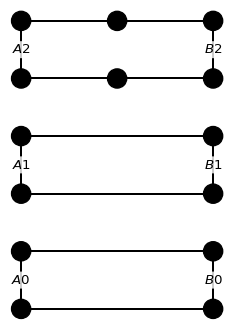</p>
</div></td>
</tr>
</tbody>
</table>

- **Molecular Protobits Matrix**

``` python
display_inline(r"X_{proto}", "=", x_proto.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ X_{proto} =  \begin{array}{r|cccccccc|}
\text{} &amp; \text{``000''} &amp; \text{``001''} &amp; \text{``010''}
&amp; \text{``011''} &amp; \text{``100''} &amp; \text{``101''} &amp;
\text{``110''} &amp; \text{``111''} \\  \hline \text{``000''} &amp; 0
&amp; 0 &amp; 0 &amp; 0 &amp; 1 &amp; 0 &amp; 0 &amp; 0 \\
\text{``001''} &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 1 &amp; 0
&amp; 0 \\ \text{``010''} &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp;
0 &amp; 1 &amp; 0 \\ \text{``011''} &amp; 0 &amp; 0 &amp; 0 &amp; 0
&amp; 0 &amp; 0 &amp; 0 &amp; 1 \\ \text{``100''} &amp; 1 &amp; 0 &amp;
0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 \\ \text{``101''} &amp; 0
&amp; 1 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 \\
\text{``110''} &amp; 0 &amp; 0 &amp; 1 &amp; 0 &amp; 0 &amp; 0 &amp; 0
&amp; 0 \\ \text{``111''} &amp; 0 &amp; 0 &amp; 0 &amp; 1 &amp; 0 &amp;
0 &amp; 0 &amp; 0 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

------------------------------------------------------------------------

### The Y Gate (Pauli-Y / Bit-and-Phase-Flip)

The $Y$ operator flips the bit and simultaneously introduces an
imaginary phase shift. It corresponds to a $\pi$ ($180^\circ$) rotation
around the $Y$-axis of the Bloch sphere:

$$Y = -i |1\rangle\langle 0| + i |0\rangle\langle 1| = \begin{bmatrix} 0 & -i \\ i & 0 \end{bmatrix}$$

- **Truth Table**  
  $$
  \begin{array}{|c|c|}
  \hline
  \mathbf{Input\ (Protobits\ \rightarrow\ Qubit)} & \mathbf{Output\ (Protobits\ \rightarrow\ Qubit)} \\
  \hline
  \text{``000''} \longrightarrow \begin{bmatrix} 1 \\ 0 \end{bmatrix} & \text{``110''} \longrightarrow \begin{bmatrix} 0 \\ i \end{bmatrix} \\
  \hline
  \text{``001''} \longrightarrow \begin{bmatrix} -1 \\ 0 \end{bmatrix} & \text{``111''} \longrightarrow \begin{bmatrix} 0 \\ -i \end{bmatrix} \\
  \hline
  \text{``010''} \longrightarrow \begin{bmatrix} i \\ 0 \end{bmatrix} & \text{``101''} \longrightarrow \begin{bmatrix} 0 \\ -1 \end{bmatrix} \\
  \hline
  \text{``011''} \longrightarrow \begin{bmatrix} -i \\ 0 \end{bmatrix} & \text{``100''} \longrightarrow \begin{bmatrix} 0 \\ 1 \end{bmatrix} \\
  \hline
  \text{``100''} \longrightarrow \begin{bmatrix} 0 \\ 1 \end{bmatrix} & \text{``011''} \longrightarrow \begin{bmatrix} -i \\ 0 \end{bmatrix} \\
  \hline
  \text{``101''} \longrightarrow \begin{bmatrix} 0 \\ -1 \end{bmatrix} & \text{``010''} \longrightarrow \begin{bmatrix} i \\ 0 \end{bmatrix} \\
  \hline
  \text{``110''} \longrightarrow \begin{bmatrix} 0 \\ i \end{bmatrix} & \text{``000''} \longrightarrow \begin{bmatrix} 1 \\ 0 \end{bmatrix} \\
  \hline
  \text{``111''} \longrightarrow \begin{bmatrix} 0 \\ -i \end{bmatrix} & \text{``001''} \longrightarrow \begin{bmatrix} -1 \\ 0 \end{bmatrix} \\
  \hline
  \end{array}
  $$

- **Logic Schematic**

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # ==========================================
    # 1. Inputs
    # ==========================================
    in_a2 = d.add(elm.Line().right(1.5).label("$A_2$", loc="left"))
    in_a1 = d.add(elm.Line().right(1.0).at((in_a2.start[0], in_a2.start[1] - 1.8)).label("$A_1$", loc="left"))
    in_a0 = d.add(elm.Line().right(0.5).at((in_a2.start[0], in_a2.start[1] - 3.4)).label("$A_0$", loc="left"))

    # ==========================================
    # 2. Connection for XOR on A0
    # ==========================================
    # Tapping points on A2 and A1
    d.add(elm.Dot().at(in_a2.end))
    d.add(elm.Dot().at(in_a1.end))

    # NOT gates on A2 and A1
    not_a2 = d.add(logic.Not().right().at(in_a2.end))
    not_a1 = d.add(logic.Not().right().at(in_a1.end))

    # A2' and A1' outputs
    d.add(elm.Line().right(2.2).at(not_a2.out).label("$B_2$", loc="right"))
    d.add(elm.Line().right(2.2).at(not_a1.out).label("$B_1$", loc="right"))

    # ==========================================
    # 3. 3-input XOR gate for A0'
    # ==========================================
    # XOR gate position at the bottom
    xor_gate = d.add(
        logic.Xor(inputs=3)
        .right()
        .at((in_a0.end[0] + 1.8, in_a0.end[1]+(1/3)))
    )

    # Connection from A2 to XOR.in1 (top)
    d.add(elm.Wire("|-").at(in_a2.end).to(xor_gate.in1))

    # Connection from A1 to XOR.in2 (middle)
    d.add(elm.Wire("|-").at(in_a1.end).to(xor_gate.in2))

    # Connection from A0 to XOR.in3 (bottom)
    d.add(elm.Wire("|-").at(in_a0.end).to(xor_gate.in3))

    # A0' Output
    d.add(elm.Line().right(1.5).at(xor_gate.out).label("$B_0$", loc="right"))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

- **Molecular Equivalent**

``` python
# Create a conjugated carbon circuit
mol = CarbonMolecule("Y gate")

# Add atoms
c1 = mol.add_atom(x=-0.3, y=2.0)
c2 = mol.add_atom(x=0.3, y=2.0)
c3 = mol.add_atom(x=-0.75, y=1.5)
c4 = mol.add_atom(x=0.75, y=1.5)
c5 = mol.add_atom(x=-0.3, y=1.0)
c6 = mol.add_atom(x=0.3, y=1.0)
c7 = mol.add_atom(x=-0.75, y=0.5)
c8 = mol.add_atom(x=0.75, y=0.5)
c9 = mol.add_atom(x=-0.75, y=0.0)
c10 = mol.add_atom(x=0.75, y=0.0)
c11 = mol.add_atom(x=-0.3, y=-0.5)
c12 = mol.add_atom(x=0.3, y=-0.5)
c13 = mol.add_atom(x=-0.75, y=-1.0)
c14 = mol.add_atom(x=0.75, y=-1.0)
c15 = mol.add_atom(x=-0.3, y=-1.5)
c16 = mol.add_atom(x=0.3, y=-1.5)

# Add bonds
b1 = mol.add_bond(c1, c2, order="single", label="$B2$")
b2 = mol.add_bond(c1, c3, order="single", label="$A2$")
b3 = mol.add_bond(c2, c4, order="single")
b4 = mol.add_bond(c3, c5, order="single")
b5 = mol.add_bond(c4, c6, order="single")
b6 = mol.add_bond(c5, c6, order="single", label="$A0$")
b7 = mol.add_bond(c3, c7, order="single")
b8 = mol.add_bond(c4, c8, order="single")
b9 = mol.add_bond(c5, c7, order="single")
b10 = mol.add_bond(c6, c8, order="single")
b11 = mol.add_bond(c7, c9, order="single")
b12 = mol.add_bond(c8, c10, order="single")
b13 = mol.add_bond(c9, c11, order="single")
b14 = mol.add_bond(c10, c12, order="single")
b15 = mol.add_bond(c11, c12, order="single", label="$B0$")
b16 = mol.add_bond(c11, c13, order="single")
b17 = mol.add_bond(c12, c14, order="single")
b18 = mol.add_bond(c9, c13, order="single")
b19 = mol.add_bond(c10, c14, order="single")
b19 = mol.add_bond(c13, c15, order="single", label="$A1$")
b19 = mol.add_bond(c14, c16, order="single")
b19 = mol.add_bond(c15, c16, order="single", label="$B1$")

mol.draw() 
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>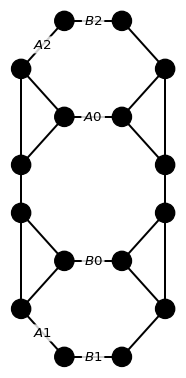</p>
</div></td>
</tr>
</tbody>
</table>

Here are the 8 resonance states that prove this molecule is indeed
equivalent to the truth table:

``` python
all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>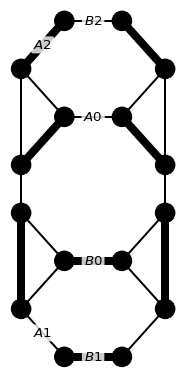</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>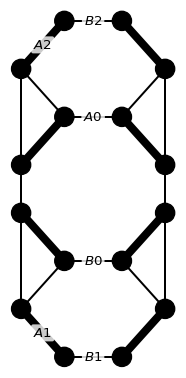</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>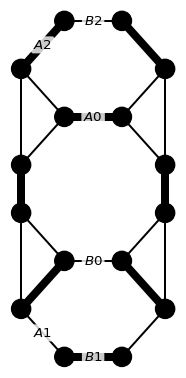</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>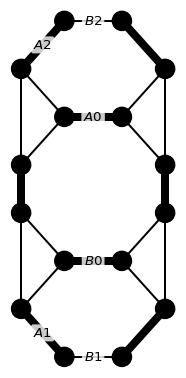</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>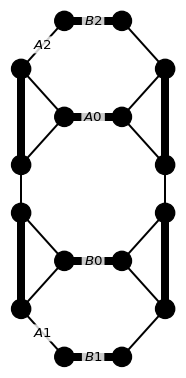</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>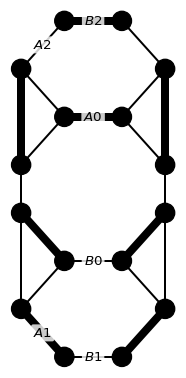</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>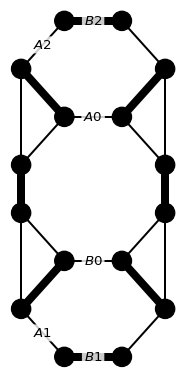</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>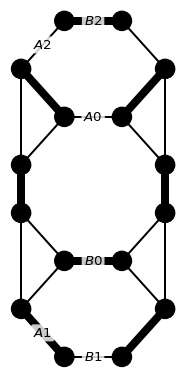</p>
</div></td>
</tr>
</tbody>
</table>

- **Molecular Protobits Matrix**

``` python
display_inline(r"Y_{proto}", "=", y_proto.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ Y_{proto} =  \begin{array}{r|cccccccc|}
\text{} &amp; \text{``000''} &amp; \text{``001''} &amp; \text{``010''}
&amp; \text{``011''} &amp; \text{``100''} &amp; \text{``101''} &amp;
\text{``110''} &amp; \text{``111''} \\  \hline \text{``000''} &amp; 0
&amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 1 &amp; 0 \\
\text{``001''} &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0
&amp; 1 \\ \text{``010''} &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp;
1 &amp; 0 &amp; 0 \\ \text{``011''} &amp; 0 &amp; 0 &amp; 0 &amp; 0
&amp; 1 &amp; 0 &amp; 0 &amp; 0 \\ \text{``100''} &amp; 0 &amp; 0 &amp;
0 &amp; 1 &amp; 0 &amp; 0 &amp; 0 &amp; 0 \\ \text{``101''} &amp; 0
&amp; 0 &amp; 1 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 \\
\text{``110''} &amp; 1 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0
&amp; 0 \\ \text{``111''} &amp; 0 &amp; 1 &amp; 0 &amp; 0 &amp; 0 &amp;
0 &amp; 0 &amp; 0 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

------------------------------------------------------------------------

### The Z Gate (Pauli-Z / Phase-Flip)

The $Z$ operator leaves $|0\rangle$ unchanged and flips the phase of
$|1\rangle$ by multiplying it by $-1$. It corresponds to a $\pi$
($180^\circ$) rotation around the $Z$-axis of the Bloch sphere:

$$Z = |0\rangle\langle 0| - |1\rangle\langle 1| = \begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix}$$

- **Truth Table** $$
  \begin{array}{|c|c|}
  \hline
  \mathbf{Input\ (Protobits\ \rightarrow\ Qubit)} & \mathbf{Output\ (Protobits\ \rightarrow\ Qubit)} \\
  \hline
  \text{``000''} \longrightarrow \begin{bmatrix} 1 \\ 0 \end{bmatrix} & \text{``000''} \longrightarrow \begin{bmatrix} 1 \\ 0 \end{bmatrix} \\
  \hline
  \text{``001''} \longrightarrow \begin{bmatrix} -1 \\ 0 \end{bmatrix} & \text{``001''} \longrightarrow \begin{bmatrix} -1 \\ 0 \end{bmatrix} \\
  \hline
  \text{``010''} \longrightarrow \begin{bmatrix} i \\ 0 \end{bmatrix} & \text{``010''} \longrightarrow \begin{bmatrix} i \\ 0 \end{bmatrix} \\
  \hline
  \text{``011''} \longrightarrow \begin{bmatrix} -i \\ 0 \end{bmatrix} & \text{``011''} \longrightarrow \begin{bmatrix} -i \\ 0 \end{bmatrix} \\
  \hline
  \text{``100''} \longrightarrow \begin{bmatrix} 0 \\ 1 \end{bmatrix} & \text{``101''} \longrightarrow \begin{bmatrix} 0 \\ -1 \end{bmatrix} \\
  \hline
  \text{``101''} \longrightarrow \begin{bmatrix} 0 \\ -1 \end{bmatrix} & \text{``100''} \longrightarrow \begin{bmatrix} 0 \\ 1 \end{bmatrix} \\
  \hline
  \text{``110''} \longrightarrow \begin{bmatrix} 0 \\ i \end{bmatrix} & \text{``111''} \longrightarrow \begin{bmatrix} 0 \\ -i \end{bmatrix} \\
  \hline
  \text{``111''} \longrightarrow \begin{bmatrix} 0 \\ -i \end{bmatrix} & \text{``110''} \longrightarrow \begin{bmatrix} 0 \\ i \end{bmatrix} \\
  \hline
  \end{array}
  $$
- **Logic Schematic**

``` python
# Initialize canvas for the Pauli-Z logic circuit
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # 1. Line A2 (MSB) -> Straight wire with a branch tap going down to the XOR
    line_a2 = d.add(elm.Line().right(4.5).label("$A_2$", loc="left").label("$B_2$", loc="right"))
    
    # 2. Line A1 (Middle) -> Pure straight wire (Identity)
    y_a1 = line_a2.start[1] - 1.5
    d.add(
        elm.Line()
        .right(4.5)
        .at((line_a2.start[0], y_a1))
        .label("$A_1$", loc="left")
        .label("$B_1$", loc="right")
    )

    # 3. Line A0 (LSB) -> Passes through a XOR gate controlled by A2
    y_a0 = line_a2.start[1] - 3.0
    
    # Place the XOR gate on line A0
    xor_gate = d.add(logic.Xor().right().at((line_a2.start[0] + 2.0, y_a0 + 0.25)))
    
    # Lead wire from Input A0 to XOR bottom input (in2)
    d.add(elm.Wire("-").at((line_a2.start[0] , y_a0)).to(xor_gate.in2).label("$A_0$", loc="left"))
    
    # Output wire from XOR to A0'
    d.add(elm.Line().at(xor_gate.out).to((line_a2.end[0], y_a0 + 0.25)).label("$B_0$", loc="right"))

    # 4. Control wire from Line A2 down into XOR top input (in1)
    tap_x = line_a2.start[0] + 1.2
    d.add(elm.Dot().at((tap_x, line_a2.start[1]))) # Branch junction on A2
    d.add(elm.Line().down(2.5).at((tap_x, line_a2.start[1])))
    d.add(elm.Wire("|-").to(xor_gate.in1))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

- **Molecular Equivalent**

``` python
# Create a conjugated carbon circuit
mol = CarbonMolecule("Z gate")

# Add atoms
c1 = mol.add_atom(x=-0.5, y=2.0)
c2 = mol.add_atom(x=0.5, y=2.0)
c3 = mol.add_atom(x=-1.0, y=1.5)
c4 = mol.add_atom(x=1.0, y=1.5)
c5 = mol.add_atom(x=-0.5, y=1.0)
c6 = mol.add_atom(x=0.5, y=1.0)
c7 = mol.add_atom(x=-1.0, y=0.5)
c8 = mol.add_atom(x=1.0, y=0.5)
c9 = mol.add_atom(x=-1.0, y=0.0)
c10 = mol.add_atom(x=1.0, y=0.0)
c11 = mol.add_atom(x=-1.0, y=-0.5)
c12 = mol.add_atom(x=1.0, y=-0.5)

# Add bonds
b1 = mol.add_bond(c1, c2, order="single")
b2 = mol.add_bond(c1, c3, order="single", label="$A2$")
b3 = mol.add_bond(c2, c4, order="single", label="$B2$")
b4 = mol.add_bond(c3, c5, order="single")
b5 = mol.add_bond(c4, c6, order="single")
b6 = mol.add_bond(c5, c6, order="single", label="$B0$")
b7 = mol.add_bond(c3, c7, order="single")
b8 = mol.add_bond(c4, c8, order="single")
b9 = mol.add_bond(c7, c5, order="single")
b10 = mol.add_bond(c8, c6, order="single")
b11 = mol.add_bond(c7, c8, order="single", label="$A0$")
b12 = mol.add_bond(c9, c10, order="single")
b13 = mol.add_bond(c10, c12, order="single", label="$B1$")
b14 = mol.add_bond(c12, c11, order="single")
b15 = mol.add_bond(c11, c9, order="single", label="$A1$")

mol.draw() 
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>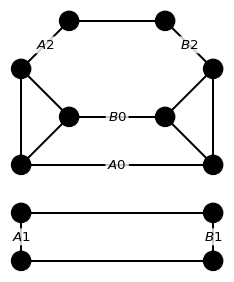</p>
</div></td>
</tr>
</tbody>
</table>

- **Molecular Protobits Matrix**

``` python
display_inline(r"Z_{proto}", "=", z_proto.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ Z_{proto} =  \begin{array}{r|cccccccc|}
\text{} &amp; \text{``000''} &amp; \text{``001''} &amp; \text{``010''}
&amp; \text{``011''} &amp; \text{``100''} &amp; \text{``101''} &amp;
\text{``110''} &amp; \text{``111''} \\  \hline \text{``000''} &amp; 1
&amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 \\
\text{``001''} &amp; 0 &amp; 1 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0
&amp; 0 \\ \text{``010''} &amp; 0 &amp; 0 &amp; 1 &amp; 0 &amp; 0 &amp;
0 &amp; 0 &amp; 0 \\ \text{``011''} &amp; 0 &amp; 0 &amp; 0 &amp; 1
&amp; 0 &amp; 0 &amp; 0 &amp; 0 \\ \text{``100''} &amp; 0 &amp; 0 &amp;
0 &amp; 0 &amp; 0 &amp; 1 &amp; 0 &amp; 0 \\ \text{``101''} &amp; 0
&amp; 0 &amp; 0 &amp; 0 &amp; 1 &amp; 0 &amp; 0 &amp; 0 \\
\text{``110''} &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0
&amp; 1 \\ \text{``111''} &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp;
0 &amp; 1 &amp; 0 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

------------------------------------------------------------------------

### The S Gate (Phase Gate / $\pi/2$ Rotation)

The $S$ gate leaves $|0\rangle$ unchanged and introduces a $\pi/2$
($90^\circ$) phase rotation on $|1\rangle$, multiplying it by $i$. It
corresponds to a quarter-turn rotation around the $Z$-axis of the Bloch
sphere:

$$S = |0\rangle\langle 0| + i |1\rangle\langle 1| = \begin{bmatrix} 1 & 0 \\ 0 & i \end{bmatrix}$$

- **Truth Table**  
  $$
  \begin{array}{|c|c|}
  \hline
  \mathbf{Input\ (Protobits\ \rightarrow\ Qubit)} & \mathbf{Output\ (Protobits\ \rightarrow\ Qubit)} \\
  \hline
  \text{``000''} \longrightarrow \begin{bmatrix} 1 \\ 0 \end{bmatrix} & \text{``000''} \longrightarrow \begin{bmatrix} 1 \\ 0 \end{bmatrix} \\
  \hline
  \text{``001''} \longrightarrow \begin{bmatrix} -1 \\ 0 \end{bmatrix} & \text{``001''} \longrightarrow \begin{bmatrix} -1 \\ 0 \end{bmatrix} \\
  \hline
  \text{``010''} \longrightarrow \begin{bmatrix} i \\ 0 \end{bmatrix} & \text{``010''} \longrightarrow \begin{bmatrix} i \\ 0 \end{bmatrix} \\
  \hline
  \text{``011''} \longrightarrow \begin{bmatrix} -i \\ 0 \end{bmatrix} & \text{``011''} \longrightarrow \begin{bmatrix} -i \\ 0 \end{bmatrix} \\
  \hline
  \text{``100''} \longrightarrow \begin{bmatrix} 0 \\ 1 \end{bmatrix} & \text{``110''} \longrightarrow \begin{bmatrix} 0 \\ i \end{bmatrix} \\
  \hline
  \text{``101''} \longrightarrow \begin{bmatrix} 0 \\ -1 \end{bmatrix} & \text{``111''} \longrightarrow \begin{bmatrix} 0 \\ -i \end{bmatrix} \\
  \hline
  \text{``110''} \longrightarrow \begin{bmatrix} 0 \\ i \end{bmatrix} & \text{``101''} \longrightarrow \begin{bmatrix} 0 \\ -1 \end{bmatrix} \\
  \hline
  \text{``111''} \longrightarrow \begin{bmatrix} 0 \\ -i \end{bmatrix} & \text{``100''} \longrightarrow \begin{bmatrix} 0 \\ 1 \end{bmatrix} \\
  \hline
  \end{array}
  $$

- **Logic Schematic**

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # Vertical coordinates of the 3 lines
    y2, y1, y0 = 4.0, 2.0, 0.0
    x_in = 0.0

    # ==========================================
    # 1. Logic gates
    # ==========================================
    # AND gate for (A2 AND A1)
    and_gate = d.add(logic.And().right().at((3.0, 1.0)))

    # XOR gate for A1' = A1 XOR A2
    xor_a1 = d.add(logic.Xor().right().at((6.0, y1)))

    # XOR gate for A0' = A0 XOR (A2 AND A1)
    xor_a0 = d.add(logic.Xor().right().at((6.0, y0 + 0.25)))

    # ==========================================
    # 2. Line A2 (MSB) wiring -> Pure identity to A2'
    # ==========================================
    d.add(elm.Line().right(8.0).at((x_in, y2)).label("$A_2$", loc="left").label("$B_2$", loc="right"))
    
    # Branch-off points on line A2
    d.add(elm.Dot().at((1.5, y2)))
    d.add(elm.Wire("|-").at((1.5, y2)).to(and_gate.in1))
    
    d.add(elm.Dot().at((4.5, y2)))
    d.add(elm.Wire("|-").at((4.5, y2)).to(xor_a1.in1))

    # ==========================================
    # 3. Line A1 Wiring
    # ==========================================
    d.add(elm.Line().right(1.8).at((x_in, y1)).label("$A_1$", loc="left"))
    d.add(elm.Dot().at((1.8, y1)))
    
    # Branching to the AND gate
    d.add(elm.Wire("|-").at((1.8, y1)).to(and_gate.in2))
    
    # Main lead to the XOR gate of A1
    d.add(elm.Wire("-|").at((1.8, y1)).to(xor_a1.in2))
    
    # A1' Output
    d.add(elm.Line().right(1.5).at(xor_a1.out).label("$B_1$", loc="right"))

    # ==========================================
    # 4. Line A0 (LSB) Wiring
    # ==========================================
    # Input A0 to the bottom input of xor_a0
    d.add(elm.Line().at((x_in, y0)).to(xor_a0.in2).label("$A_0$", loc="left"))

    # Output from the AND gate to the top input of xor_a0
    d.add(elm.Wire("-|").at(and_gate.out).to(xor_a0.in1))

    # A0' Output
    d.add(elm.Line().right(1.5).at(xor_a0.out).label("$B_0$", loc="right"))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

- **Molecular Equivalent**

``` python
# Create a conjugated carbon circuit
mol = CarbonMolecule("S gate")

# Add atoms
c1 = mol.add_atom(x=-1.0, y=1.0)
c2 = mol.add_atom(x=-0.5, y=1.0)
c3 = mol.add_atom(x=0.0, y=1.0)
c4 = mol.add_atom(x=0.5, y=1.0)
c5 = mol.add_atom(x=1.0, y=1.0)
c6 = mol.add_atom(x=-1.5, y=0.75)
c7 = mol.add_atom(x=-1.7, y=0.25)
c8 = mol.add_atom(x=-0.95, y=0.0)
c9 = mol.add_atom(x=-0.35, y=0.0)
c10 = mol.add_atom(x=0.6, y=0.35)
c11 = mol.add_atom(x=1.0, y=0.5)
c12 = mol.add_atom(x=1.5, y=0.5)
c13 = mol.add_atom(x=-1.3, y=0.0)
c14 = mol.add_atom(x=0.1, y=0.0)
c15 = mol.add_atom(x=0.6, y=-0.35)
c16 = mol.add_atom(x=-1.7, y=-0.25)
c17 = mol.add_atom(x=1.0, y=-0.5)
c18 = mol.add_atom(x=1.5, y=-0.5)
c19 = mol.add_atom(x=-1.5, y=-0.75)
c20 = mol.add_atom(x=-1.0, y=-1.0)
c21 = mol.add_atom(x=0.5, y=-1.0)
c22 = mol.add_atom(x=1.0, y=-1.0)

# Add bonds
b1 = mol.add_bond(c1, c2, order="single")
b2 = mol.add_bond(c1, c6, order="single", label="$A2$")
b3 = mol.add_bond(c2, c3, order="single", label="$B2$")
b4 = mol.add_bond(c3, c4, order="single")
b5 = mol.add_bond(c4, c5, order="single")
b6 = mol.add_bond(c4, c14, order="single")
b7 = mol.add_bond(c5, c11, order="single")
b8 = mol.add_bond(c5, c12, order="single")
b9 = mol.add_bond(c6, c7, order="single")
b10 = mol.add_bond(c7, c13, order="single")
b11 = mol.add_bond(c7, c16, order="single")
b12 = mol.add_bond(c8, c9, order="single", label="$B1$")
b13 = mol.add_bond(c8, c13, order="single")
b14 = mol.add_bond(c9, c14, order="single")
b15 = mol.add_bond(c10, c11, order="single")
b16 = mol.add_bond(c10, c15, order="single", label="$B0$")
b17 = mol.add_bond(c11, c12, order="single")
b18 = mol.add_bond(c12, c18, order="single", label="$A0$")
b19 = mol.add_bond(c13, c16, order="single")
b20 = mol.add_bond(c14, c21, order="single")
b21 = mol.add_bond(c15, c17, order="single")
b22 = mol.add_bond(c16, c19, order="single")
b23 = mol.add_bond(c17, c18, order="single")
b24 = mol.add_bond(c17, c22, order="single")
b25 = mol.add_bond(c18, c22, order="single")
b26 = mol.add_bond(c19, c20, order="single", label="$A1$")
b27 = mol.add_bond(c20, c21, order="single")
b28 = mol.add_bond(c21, c22, order="single")

mol.draw(scale=1) 
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>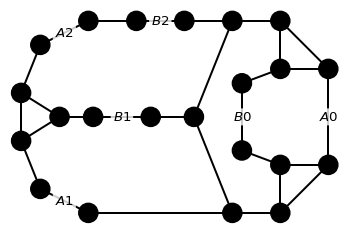</p>
</div></td>
</tr>
</tbody>
</table>

And here are the 8 resonance states that prove this molecule is indeed
equivalent to the truth table:

``` python
all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>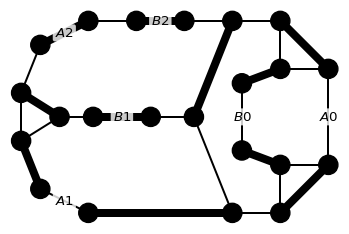</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>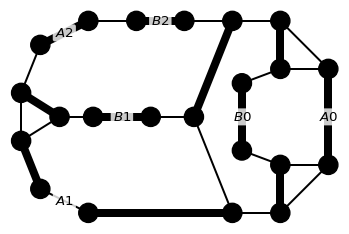</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>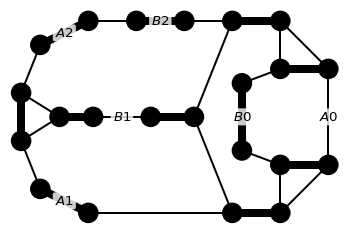</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>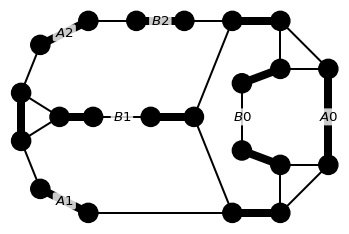</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>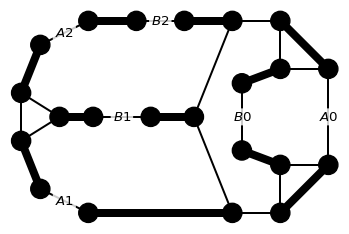</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>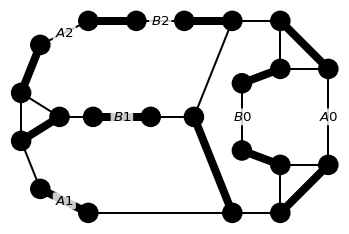</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>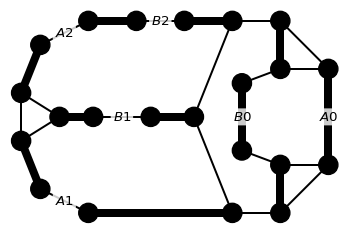</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>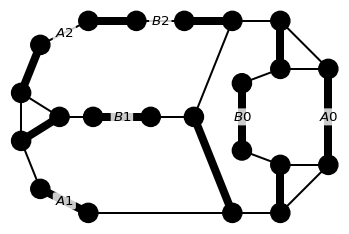</p>
</div></td>
</tr>
</tbody>
</table>

- **Molecular Protobits Matrix**

``` python
display_inline(r"S_{proto}", "=", s_proto.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ S_{proto} =  \begin{array}{r|cccccccc|}
\text{} &amp; \text{``000''} &amp; \text{``001''} &amp; \text{``010''}
&amp; \text{``011''} &amp; \text{``100''} &amp; \text{``101''} &amp;
\text{``110''} &amp; \text{``111''} \\  \hline \text{``000''} &amp; 1
&amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 \\
\text{``001''} &amp; 0 &amp; 1 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0
&amp; 0 \\ \text{``010''} &amp; 0 &amp; 0 &amp; 1 &amp; 0 &amp; 0 &amp;
0 &amp; 0 &amp; 0 \\ \text{``011''} &amp; 0 &amp; 0 &amp; 0 &amp; 1
&amp; 0 &amp; 0 &amp; 0 &amp; 0 \\ \text{``100''} &amp; 0 &amp; 0 &amp;
0 &amp; 0 &amp; 0 &amp; 0 &amp; 1 &amp; 0 \\ \text{``101''} &amp; 0
&amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 1 \\
\text{``110''} &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 1 &amp; 0
&amp; 0 \\ \text{``111''} &amp; 0 &amp; 0 &amp; 0 &amp; 0 &amp; 1 &amp;
0 &amp; 0 &amp; 0 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

------------------------------------------------------------------------

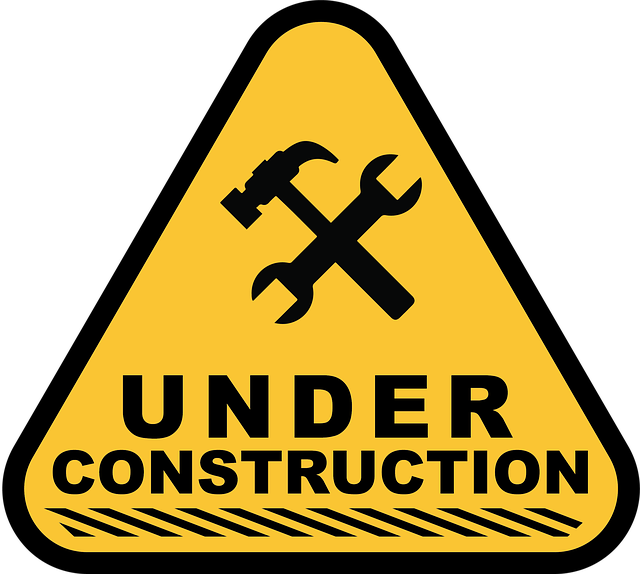

## Portes logiques superposées

Hadamard

T

------------------------------------------------------------------------

## Portes logiques avec plus d’une entrée

Swap

Cnot

### Portes logiques contrôlées

Cz

Toffoli (Ccnot)

### Portes classiques avec une porte Toffoli

------------------------------------------------------------------------

## Rotations de base

$R_x(\pi)$

$R_y(\pi)$

$R_z(\pi)$

## Phase

$Ph(\pi)$

$Ph(\frac{\pi}{2})$

------------------------------------------------------------------------

## Fraction de rotation

------------------------------------------------------------------------

## Portes logiques racines carrés

------------------------------------------------------------------------

## Circuits de mesure

### Échantillonage

### Recuit Simulé

------------------------------------------------------------------------

## Exemples classiques

Retour de phase quantique.

Transformations de fourrier quantique.

------------------------------------------------------------------------

## 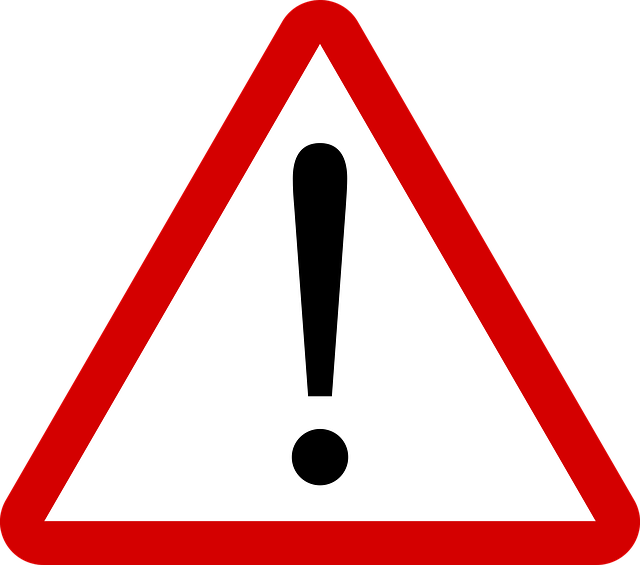 Speculations & Wild Thoughts

- Quarks of Light: Modeling the Photon as a Protobit Triplet

If a standard quantum qubit can be faithfully mapped onto a 3-protobit
manifold, could the fundamental gauge bosons of the universe—starting
with the photon—themselves be composite topologies of three protobits?

Just as particle physics once viewed hadrons as elementary until they
revealed their internal quark triplets, the polarization states,
helicity, and phase of light (traditionally mapped onto the Poincaré
sphere) might simply be the macroscopic shadow projected by an internal,
geometric resonance cavity.

What if a photon is not an infinitely small, point-like excitation of a
continuous field, but an autonomous, self-closing topological loop of
three coupled protobits traversing spacetime?

A prime candidate for this internal resonance cavity is the **truncated
tetrahedron** topology, owing to its exact, self-reinforcing manifold of
**8 stable resonance modes**.

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Truncated Tetrahedron")

# Add atoms
c1 = mol.add_atom(x=-0.25, y=1.0)
c2 = mol.add_atom(x=0.25, y=1.0)
c3 = mol.add_atom(x=0.0, y=0.6)
c4 = mol.add_atom(x=0.0, y=0.2)
c5 = mol.add_atom(x=-0.2, y=-0.25)
c6 = mol.add_atom(x=0.2, y=-0.25)
c7 = mol.add_atom(x=-0.55, y=-0.6)
c8 = mol.add_atom(x=0.55, y=-0.6)
c9 = mol.add_atom(x=-1.2, y=-0.7)
c10 = mol.add_atom(x=1.2, y=-0.7)
c11 = mol.add_atom(x=-0.65, y=-1.0)
c12 = mol.add_atom(x=0.65, y=-1.0)

# Add bonds
b1 = mol.add_bond(c1, c2, order="single")
b2 = mol.add_bond(c2, c3, order="single")
b3 = mol.add_bond(c3, c1, order="single")

b4 = mol.add_bond(c4, c6, order="single")
b5 = mol.add_bond(c6, c5, order="single")
b6 = mol.add_bond(c5, c4, order="single")

b7 = mol.add_bond(c9, c7, order="single")
b8 = mol.add_bond(c7, c11, order="single")
b9 = mol.add_bond(c11, c9, order="single")

b10 = mol.add_bond(c8, c10, order="single")
b11 = mol.add_bond(c10, c12, order="single")
b12 = mol.add_bond(c12, c8, order="single")

b13 = mol.add_bond(c1, c9, order="single", label="A0")
b14 = mol.add_bond(c2, c10, order="single", label="A1")
b15 = mol.add_bond(c11, c12, order="single", label="A2")

b16 = mol.add_bond(c3, c4, order="single")
b17 = mol.add_bond(c6, c8, order="single")
b18 = mol.add_bond(c5, c7, order="single")

all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>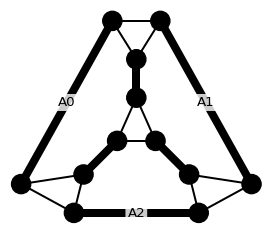</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>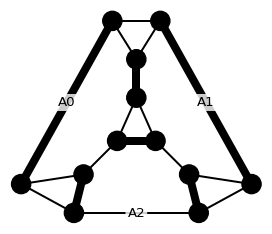</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>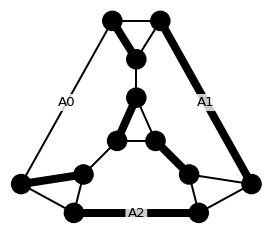</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>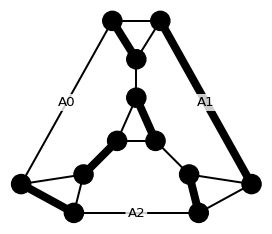</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>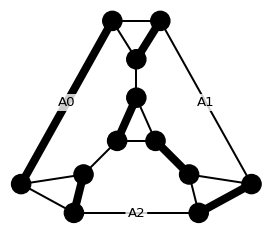</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>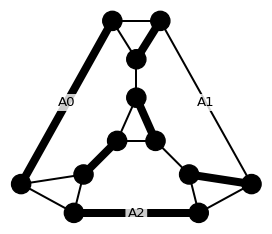</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>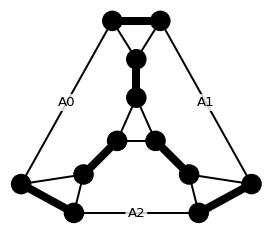</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>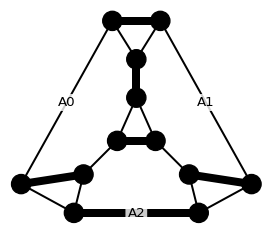</p>
</div></td>
</tr>
</tbody>
</table>

You have almost certainly seen this exact geometric shape before: **it
is the official logo of this website.**

The true *CCC* signature—our molecular, geometric way of encoding a
spark of light!

- The Universe as a Clifford Algebra of Protobits

Decomposing a qubit reveals a profound mathematical bridge: **it takes
$(m + n)$ protobits to span the $2^{m+n}$ multivector space of a
Geometric Clifford Algebra $\mathcal{C}\ell(m, n)$.**

The hierarchy of information unfolds naturally:  
\* **$\mathcal{C}\ell(0, 0)$ (1 protobit, 2 states):** The boundary
case—a classical or probabilistic boolean bit ($[1 \quad 0]$ or
$[0 \quad 1]$).  
\* **$\mathcal{C}\ell(0, 2) \cong \mathbb{H}$ lifted into
$\mathcal{C}\ell(3, 0)$ (3 protobits, 8 states):** While a standard
qubit lives in the 4-dimensional quaternionic algebra
$\mathcal{C}\ell(0, 2)$, encoding its signs and phases into non-negative
probabilities requires 3 protobits. Its 8 basis states map directly to
the **graded elements of 3D space**: 1 scalar, 3 vectors ($X, Y, Z$), 3
bivector planes, and 1 pseudoscalar ($i$).

This invites a wild cosmological conjecture: **what if physical
dimensionality simply reflects the number of entangled protobits?**  
Under this lens, 4D Minkowski spacetime ($\mathcal{C}\ell(1, 3)$)
requires 4 protobits ($2^4 = 16$ states, the Dirac algebra), while Grand
Unified models ($\mathcal{C}\ell(6)$ or $\mathcal{C}\ell(8)$) demand
just 6 to 8 entangled bonds.

Continuous complex numbers and ethereal wavefunctions are merely
emergent illusions. Reality does not compute with abstract qubits in
unphysical Hilbert spaces—**it weaves the grammar of
$\mathcal{C}\ell(m, n)$ through the physical resonance of Protobits.**

- Parallels with the I Ching

Historians of science often recall that Gottfried Wilhelm Leibniz saw
the ancient Chinese **I Ching** (*Book of Changes*) as the earliest
historical precursor to binary algebra.

Yet, when viewed through the lens of **Conjugated Carbon Computing
(CCC)**, the structural parallels become even more striking, almost
eerie:

- **Stochastic Sampling:** Both systems rely on stochastic processes
  (throwing yarrow stalks or tossing coins) to collapse possibilities
  into an observed state—mirroring quantum measurement and statistical
  p-bit relaxation.  
- **Trigrams as Protobit Triplets:** The fundamental building blocks of
  the I Ching are **Trigrams** (groups of 3 broken or unbroken lines,
  yielding $2^3 = 8$ states). This is the exact dimensional cardinality
  required by our protobit triplets ($A_2, A_1, A_0$) to span the 8
  basis states of a complete quantum qubit. The 64 Hexagrams ($2^6$)
  naturally map to a 2-qubit interacting register!  
- **Turtle Shells & Carbon Geometry:** Historically, ancient divination
  was performed by heating tortoise plastrons until they cracked into
  distinct patterns. Visually and geometrically, the natural hexagonal
  tiling of a turtle shell bears an uncanny resemblance to the fused
  aromatic rings and polygonal lattices of our molecular carbon logic
  gates.  
- **The King Wen Sequence:** When mapped as a discrete state transition
  matrix, the traditional King Wen permutation order exhibits the
  algebraic properties of a **unitary, reversible 2-input / 2-output
  Universal quantum gate**.

I will certainly not claim that ancient diviners possessed an explicit
formulation of quantum mechanics; there is zero historical evidence for
such an assertion.

However, it is deeply fascinating to realize that our modern concepts of
superposition, dual-rail binary states, and molecular resonance would
have felt astonishingly familiar to their worldview.

Perhaps when humans search for the fundamental patterns of change in
nature, all roads eventually lead back to the same underlying geometric
syntax.

------------------------------------------------------------------------

👉 **Next chapter :**  
**[“Quantum Exceptions”](../../posts/quantum-exceptions/index.html)**